---
title: Introduction to Push-Forward Generative Models -- Generative Adversarial Networks (GANs)
author: Mark Fuge
date: 'October 12 2025'
format:
    html:
        code-fold: true
        code-summary: "Show Code"
---

In this chapter, we will build geometric intuition for push-forward generative models, which are essentially trying to transport probability distributions from one space to another. We will start with simple linear maps to gain a sense of how they modify a simple 2D data space, then scale up to a small MLP GAN on a ring-of-Gaussians toy dataset. We will also talk about common metrics to evaluate generative models. Even though GANs may be comparatively simple compared to more advanced generative models that we will explore later, they will nevertheless be useful in building intuition for how push-forward generative models work.

**Learning Objectives**

By the end of this chapter, you should be able to:

1. Describe a generative model as a push-forward map from a latent distribution, and say which of the three operations (forward map, inverse map, density) a GAN actually does.
2. Map the terms of the GAN objective to the discriminator and generator steps of the training loop.
3. Explain how each network's update depends on the other: the generator moves its samples up the discriminator's logit in an attempt to fool the discriminator, and the discriminator reshapes its logit around the current samples in an attempt to classify them correctly.
4. Explain why a single summary statistic of the samples, such as the chapter's variance-based diversity, cannot certify coverage or quality.
5. Check conditional generated samples against the engineering requirement with a simulator and a constraint check.

In [1]:
# Setup and Imports (shared utilities)
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import os
from matplotlib import pyplot as plt

# Import shared utilities from the local module
from gen_models_utilities import (
    RNG_SEED, device, _compute_axis_limits, create_ring_gaussians, 
    GanHistory, make_loader,
    compute_diversity_metric, plot_model_diagnostics, plot_latent_interpolation,
    make_conditional_loader_onehot, plot_conditional_samples_discrete
)

# get the location of this file
main_fpath = os.path.abspath('')
os.chdir(main_fpath)

# Optional interactive widgets
try:
    from ipywidgets import interact, FloatSlider, IntSlider
except Exception:
    interact = None
    FloatSlider = IntSlider = None



print(f"Using device: {device}")

Using device: cuda


## What are Generative Models really doing?

Fundamentally, generative models are really just functions that transform a probability distribution from one space to another -- you can think of them as "distribution transformers" or, more intuitively, as moving probability mass around in space. As an analogy, consider that you are sitting in a sandbox with a smooth mound of sand in front of you -- the 2D Gaussian that we will use below is not too far from this, actually. A generative model is kind of like your hands, which you can use to push the sand around, creating hills and valleys, and moving the sand from one place to another. In this way, we are essentially moving the probability mass (sand, in this analogy) from a simple distribution (the smooth mound of sand) to a more complex distribution (the hills and valleys that you create with your hands). Different models that we will explore later (e.g., VAEs, normalizing flows, diffusion models) have different ways of doing this, but the core goal is the same, and they essentially all try to do one or more of three operations:

- $f(z) \rightarrow x$: Mapping points from one space (typically called the *latent space*) to another (typically, the *data space*).
- $f^{-1}(x) \rightarrow z$: Mapping points from data space back to latent space.
- $p(x) \Leftrightarrow  p(z)$: Mapping probability densities from data space to latent space (and vice versa).

As we go forward, we will see how different types of models are better or worse at these different operations, and, in some cases, how they can be combined to create more powerful models.

## Basic Deterministic Push-Forward Models: From Latent Space to Data Space

A push-forward generative model defines a mapping $x = f(z)$, where $z$ is sampled from a simple latent distribution (often a standard Gaussian, though it need not be) and $f$ is a deterministic function (e.g., linear map or neural network).

We'll start with a 2D latent $z \sim N(0, I)$ (i.e., a standard Gaussian) and inspect how different choices of $f$ reshape the distribution in data space. In this case, the latent space is 2D and the data space is also 2D, so we can visualize both spaces directly, however, in general, the latent space is often lower-dimensional than the data space.

In [2]:
def plot_pushforward(z: np.ndarray, x: np.ndarray, title: str = "Linear push-forward"):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].scatter(z[:, 0], z[:, 1], s=8, alpha=0.35, color='tab:gray')
    axes[0].set_title('Latent samples z ~ N(0, I)')
    axes[0].set_xlabel('z1')
    axes[0].set_ylabel('z2')
    axes[0].axis('equal')
    axes[0].grid(True, alpha=0.3)

    axes[1].scatter(x[:, 0], x[:, 1], s=8, alpha=0.5, color='tab:blue')
    axes[1].set_title(title)
    axes[1].set_xlabel('x1')
    axes[1].set_ylabel('x2')
    axes[1].axis('equal')
    axes[1].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

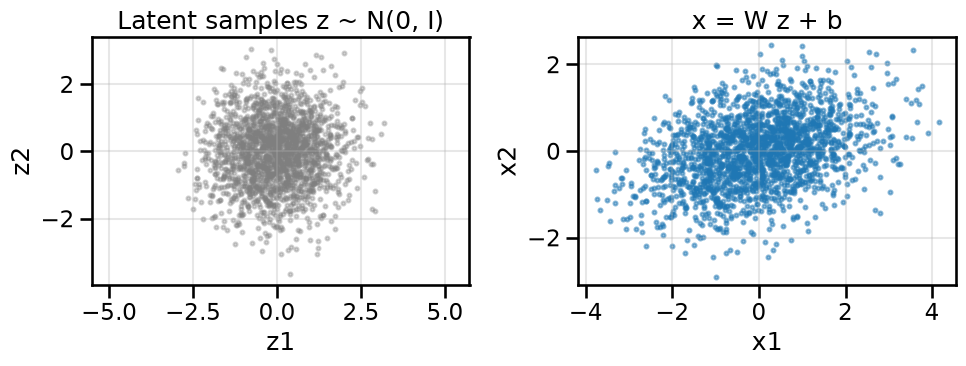

In [3]:
#| code-fold: false
# Linear push-forward demo with interactive sliders
def linear_pushforward_demo(W: np.ndarray, b: np.ndarray, n: int = 1000, seed: int = RNG_SEED):
    rng = np.random.default_rng(seed)
    z = rng.standard_normal(size=(n, 2))
    x = (z @ W.T) + b
    return z, x

# Default transform
W0 = np.array([[1.2, 0.4],[0.0, 0.8]], dtype=float)
b0 = np.array([0.0, 0.0], dtype=float)
z_lin, x_lin = linear_pushforward_demo(W0, b0, n=2000)
plot_pushforward(z_lin, x_lin, title='x = W z + b')


We can see from above that the simple linear map has slightly "moved" or shifted the location of the probability mass, just like if you were sculpting sand in your sandbox. You can play below with some of the sliders to manipulate the simple 2x2 weight matrix and 2x1 bias vector to see how this works interactively:

In [ ]:
if interact is not None:
    def _interactive_pushforward(a11=1.2, a12=0.4, a21=0.0, a22=0.8, bx=0.0, by=0.0):
        W = np.array([[a11, a12],[a21, a22]], dtype=float)
        b = np.array([bx, by], dtype=float)
        z, x = linear_pushforward_demo(W, b, n=2000)
        plot_pushforward(z, x, title=f'x = W z + b')
    interact(
        _interactive_pushforward,
        a11=FloatSlider(min=-2.0, max=2.0, step=0.05, value=1.2, description='a11'),
        a12=FloatSlider(min=-2.0, max=2.0, step=0.05, value=0.4, description='a12'),
        a21=FloatSlider(min=-2.0, max=2.0, step=0.05, value=0.0, description='a21'),
        a22=FloatSlider(min=-2.0, max=2.0, step=0.05, value=0.8, description='a22'),
        bx=FloatSlider(min=-2.0, max=2.0, step=0.05, value=0.0, description='b1'),
        by=FloatSlider(min=-2.0, max=2.0, step=0.05, value=0.0, description='b2'),
    )

interactive(children=(FloatSlider(value=1.2, description='a11', max=2.0, min=-2.0, step=0.05), FloatSlider(val…

## Toy Dataset: Ring of Gaussians

OK, now that we have some intuition for how simple linear maps can move probability mass around in space, let's try a more complex example where it is not so clear that a simple linear map will be sufficient. Below, we will create a common toy dataset consisting of a "ring of Gaussians" -- that is, several Gaussian blobs arranged in a circle. You can see from above that no combination of weights in a simple linear map will be able to move our original probability mass from a standard Gaussian to this ring of Gaussians, so we will need something more powerful. A simple starting point for this is something called a Generative Adversarial Network (GAN), which we will explore next.


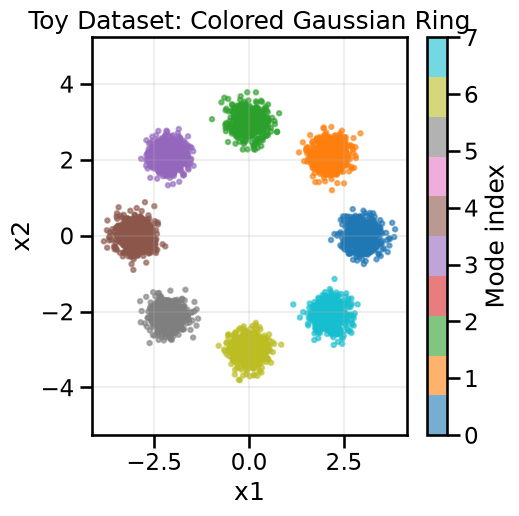

In [5]:
X_ring, y_ring = create_ring_gaussians()
plt.figure(figsize=(5.5,5.5))
sc = plt.scatter(X_ring[:,0], X_ring[:,1], c=y_ring, cmap='tab10', s=10, alpha=0.6)
plt.colorbar(sc, label='Mode index')
plt.title('Toy Dataset: Colored Gaussian Ring')
plt.xlabel('x1')
plt.ylabel('x2')
plt.axis('equal')
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

ring_latent_limits = ((-3.5, 3.5), (-3.5, 3.5))
ring_data_limits = _compute_axis_limits(X_ring)

## What is a Generative Adversarial Network (GAN)?

A Generative Adversarial Network (GAN) is a framework for training generative models using two competing neural networks: a **generator** and a **discriminator**. The generator, $G$, learns to map random noise from a latent space (e.g., $z \sim p_z(z)$ or $f(z)=x$, where $G$ functions as $f$ here) to data space, aiming to produce samples that resemble the real data. It is tempting to want to train just the Generator by minimizing Mean Squared Error between $f(z)$ and a real sample $x$, except we have one big problem for right now -- we do not know a priori which samples of $x$ correspond to which samples of $z$, and so it is not straightforward to compute this MSE.[^gan-10-1] Instead, what we will do is train a separate network, the Discriminator, that can help us push the samples produced by the Generator closer to the real data distribution.

[^gan-10-1]: Indeed, we will return to this idea in later notebooks once we have introduced the concept of Optimal Transport, which solves this mapping problem, but for now, let's assume that we don't know how to do this. 

Specifically, the discriminator, $D$, tries to distinguish between real data samples and those produced by the generator and our loss function will encourage the discriminator to become better and better at this task. In turn, the generator will be trained to produce samples that the discriminator classifies as real -- that is to try to fool the discriminator.

The two networks are trained simultaneously in something called a *minimax game*:

- The **generator** tries to "fool" the discriminator by generating realistic samples.
- The **discriminator** tries to correctly classify real vs. generated samples.

### Mathematical Formulation

The standard GAN objective, as introduced by @goodfellow2014generative, is:

$$
\min_G \max_D \; V(D, G) = \mathbb{E}_{x \sim p_{\text{data}}(x)} \left[ \log D(x) \right] + \mathbb{E}_{z \sim p_z(z)} \left[ \log (1 - D(G(z))) \right]
$$

- $p_{\text{data}}(x)$: Distribution of real data.
- $p_z(z)$: Prior distribution over latent variables (often standard normal).
- $G(z)$: Generator's output given latent input $z$.
- $D(x)$: Discriminator's estimate of the probability that $x$ is real.

The generator and discriminator are typically neural networks trained with stochastic gradient descent. The generator improves by producing samples that the discriminator cannot distinguish from real data (the second term on the right-hand side of the equation above), while the discriminator improves by getting better at distinguishing real from fake (it maximizes both terms: scoring real data high and generated data low).

Two terms from classification will help us read the training code. A classifier that gives a probability $p$ that its input is real can just as well give the *logit* of that probability, its log-odds:

$$
\operatorname{logit}(p) = \log \frac{p}{1-p}, \qquad p = \sigma(s) = \frac{1}{1 + e^{-s}}.
$$

The sigmoid $\sigma$ is the inverse of the logit: it maps a logit $s$ back to a probability. A logit of 0 means $p = 0.5$, a positive logit means "more likely real" and a negative logit means "more likely fake". A logit can take any real value, so networks usually output it instead of $p$. Our discriminator does this too: its last layer outputs a logit $\ell(x)$, and $D(x) = \sigma(\ell(x))$.

A classifier like this is trained with the *binary cross-entropy* (BCE) between a label $y \in \{0, 1\}$ and the predicted probability $p$:

$$
\mathrm{BCE}(p, y) = -\left[ y \log p + (1-y) \log (1-p) \right].
$$

Only one of the two terms is active for each sample, so the BCE is $-\log$ of the probability that the classifier gave to the correct label. It is 0 when the classifier is confident and right, and it grows without bound when the classifier is confident and wrong: $p = 0.01$ for a real sample costs $-\log 0.01 \approx 4.6$. This is the log loss from the classification losses in [Reviewing Supervised Linear Models](../../part1/reviewing_supervised_linear_models.ipynb), written for labels 0 and 1 instead of $\pm 1$.

In the training loop below, `loss_d = bce(d_real, torch.ones_like(d_real)) + bce(d_fake, torch.zeros_like(d_fake))` labels the real samples 1 and the generated samples 0. Per sample, it is $-\log D(x) - \log(1 - D(G(z)))$, which is minus the per-sample $V(D, G)$. So minimizing this loss maximizes $V$. `nn.BCEWithLogitsLoss` takes the logits `d_real` and `d_fake` and applies the sigmoid inside, which is numerically more stable than taking the log of a sigmoid in two steps.

In practice, the generator does not minimize the second term above directly. Early in training, the discriminator easily rejects fakes, so $D(G(z)) \approx 0$. There, $\log(1 - D(G(z)))$ is almost flat, and the generator gets almost no gradient. So instead of minimizing $\mathbb{E}_{z}[\log(1 - D(G(z)))]$, the generator minimizes the *non-saturating* loss:

$$
\mathcal{L}_G = -\mathbb{E}_{z \sim p_z(z)} \left[ \log D(G(z)) \right],
$$

which has the same goal (push $D(G(z))$ toward 1) but provides stronger gradients when the generator is doing badly. This is what `loss_g = bce(dg, torch.ones_like(dg))` computes in the training loop below.

Goodfellow et al. proposed this switch in the original GAN paper, in its Section 3 [@goodfellow2014generative]. The two generator losses have the same end point, $p_G = p_{\text{data}}$ with $D = 1/2$ everywhere, and both push $D(G(z))$ toward 1. But they are not the same objective. With the best discriminator for the current generator, the original minimax objective equals $-\log 4 + 2\,\mathrm{JS}(p_{\text{data}} \parallel p_G)$, so the generator minimizes the Jensen-Shannon (JS) divergence. The non-saturating loss instead follows the gradient of $\mathrm{KL}(p_G \parallel p_{\text{data}}) - 2\,\mathrm{JS}(p_{\text{data}} \parallel p_G)$ [@arjovsky2017towards]. Its reverse Kullback-Leibler (KL) term punishes samples where there are no data much more than it punishes parts of the data that get no samples. This is one reason why GANs tend to drop modes rather than produce garbage. We met both divergences, and the mode-seeking behavior of the reverse KL, in [Measuring Distribution Distances](../../part1/distribution_distance.ipynb).

## A Simple Generative Adversarial Network (GAN)

Now we will define a small GAN and see how it moves probability mass around after passing samples through the Generator. You can feel free to modify the architecture below if you like and see how that impacts the below results, but for now we will use an MLP with two hidden layers and LeakyReLU activations for both the Generator and Discriminator.

In [6]:
#| code-fold: false
class MLPGenerator(nn.Module):
    def __init__(self, noise_dim: int = 2, hidden_dim: int = 256, out_dim: int = 2):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(noise_dim, hidden_dim), nn.LeakyReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.LeakyReLU(),
            nn.Linear(hidden_dim, out_dim),
)
    def forward(self, z: torch.Tensor) -> torch.Tensor:
        return self.main(z)

class MLPDiscriminator(nn.Module):
    def __init__(self, input_dim: int = 2, hidden_dim: int = 256):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, hidden_dim), nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, 1),
)
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.main(x).squeeze(-1)

def build_generator(noise_dim=2, hidden_dim=256):
    return MLPGenerator(noise_dim=noise_dim, hidden_dim=hidden_dim).to(device)

def build_discriminator(hidden_dim=256):
    return MLPDiscriminator(hidden_dim=hidden_dim).to(device)

## Basic Training Loop
With the models defined, we will now set up the training loop to optimize both the generator and discriminator.

In [7]:
#| code-fold: false
def train_vanilla_gan(
    data: np.ndarray, *, noise_dim: int = 2, batch_size: int = 256, epochs: int = 120,
    lr_g: float = 2e-4, lr_d: float = 2e-4, hidden_dim: int = 256, print_every: int = 40) -> tuple[nn.Module, nn.Module, GanHistory]:
    # Load the data into a DataLoader for batching and make PyTorch happy
    loader = make_loader(data, batch_size)

    # Set up the basic networks
    G = build_generator(noise_dim=noise_dim, hidden_dim=hidden_dim)
    D = build_discriminator(hidden_dim=hidden_dim)
    # Instantiate the optimizers for each model
    opt_g = optim.Adam(G.parameters(), lr=lr_g, betas=(0.5, 0.999))
    opt_d = optim.Adam(D.parameters(), lr=lr_d, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    # Record the loss history for plotting later
    hist = GanHistory([], [], [], [], [])

    # Now we do the training loop for # epochs defined in `epochs`
    for ep in range(epochs):
        d_losses=[]
        g_losses=[]
        real_scores=[]
        fake_scores=[]
        for (xb,) in loader:
            # Send the data to the GPU, if using.
            xb = xb.to(device)

            # Take a Discriminator step
            z = torch.randn(xb.size(0), noise_dim, device=device)
            with torch.no_grad():
                x_fake = G(z)
            opt_d.zero_grad()
            d_real = D(xb)
            d_fake = D(x_fake)
            loss_d = bce(d_real, torch.ones_like(d_real)) + bce(d_fake, torch.zeros_like(d_fake))
            loss_d.backward()
            opt_d.step()
            d_losses.append(float(loss_d.detach().cpu().item()))
            real_scores.append(d_real.mean().item())
            fake_scores.append(d_fake.mean().item())

            # Take a Generator step
            z = torch.randn(xb.size(0), noise_dim, device=device)
            opt_g.zero_grad()
            xg = G(z)
            dg = D(xg)
            loss_g = bce(dg, torch.ones_like(dg))
            loss_g.backward()
            opt_g.step()
            g_losses.append(float(loss_g.detach().cpu().item()))
        
        # We'll record some epoch metrics
        with torch.no_grad():
            z_eval = torch.randn(2048, noise_dim, device=device)
            samples = G(z_eval)
            div = compute_diversity_metric(samples)

        # Now we'll record the metrics for plotting later and reporting
        hist.d_loss.append(float(np.mean(d_losses)))
        hist.g_loss.append(float(np.mean(g_losses)))
        hist.diversity.append(div)
        hist.real_scores.append(float(np.mean(real_scores)))
        hist.fake_scores.append(float(np.mean(fake_scores)))
        if (ep+1) % max(1, print_every) == 0 or ep==0:
            print(f"Epoch {ep+1:03d}/{epochs} | D {hist.d_loss[-1]:.3f} | G {hist.g_loss[-1]:.3f} | Div {div:.3f}")
    return G, D, hist

You can feel free to modify some of the training elements here, such as the epoch length or learning rates of the Generator or Discriminator, respectively.

In [8]:
#| code-fold: false
G, D, H = train_vanilla_gan(
    X_ring, epochs=120, batch_size=256, 
    lr_g=2e-4, lr_d=2e-4, 
    hidden_dim=256, noise_dim=2, 
    print_every=40)

Epoch 001/120 | D 1.128 | G 0.734 | Div 0.809
Epoch 040/120 | D 1.300 | G 0.769 | Div 4.310
Epoch 080/120 | D 1.340 | G 0.754 | Div 4.409
Epoch 120/120 | D 1.368 | G 0.732 | Div 4.444


OK, now the model is trained, so let's look at some basic visualizations of how it did. In the below plots, which we will re-use for other models later on, we will show four things:

- Upper Left: Any training losses for the model, as a function of training epoch. In the case of a GAN, this will plot both the Generator and Discriminator losses. This plot type allows us to assess something about the convergence and stability of training.
- Upper Right: The Sample Diversity, as a function of Epoch. This is computing and plotting the variance of $\mathbf{x}$ as a function of epoch, where $\mathbf{x}$ are samples drawn from the Generator at each epoch. This plot type allows us one way to assess whether the model is suffering from mode collapse (i.e., low diversity in the generated samples) or not.
- Lower Left: A plot of the real data samples (in light grey) and samples drawn from the Generator (in reddish-orange). This plot type allows us to visually assess how well the model is capturing the data distribution. This will be easy to compare in this simple 2D case, but will be harder in higher dimensions, and in those cases you might have to resort to just comparing selected samples or overall distribution summary statistics.
- Lower Right: This plot will vary depending on the specific model we are studying, but in this case it will show the average raw output (the logit) of the Discriminator (often called the "Critic") on real and on fake samples. A positive logit means the Discriminator thinks a sample is real, and a negative logit means it thinks the sample is fake. In the context of a GAN model, this allows us to assess how well a Generator is fooling the discriminator, since a well-trained Generator should produce samples that the Discriminator cannot tell apart from real ones, and thus both the "Real score" and "Fake score" should hover around 0, which corresponds to a probability of $\sigma(0) = 0.5$ (i.e., the Discriminator is effectively guessing randomly).


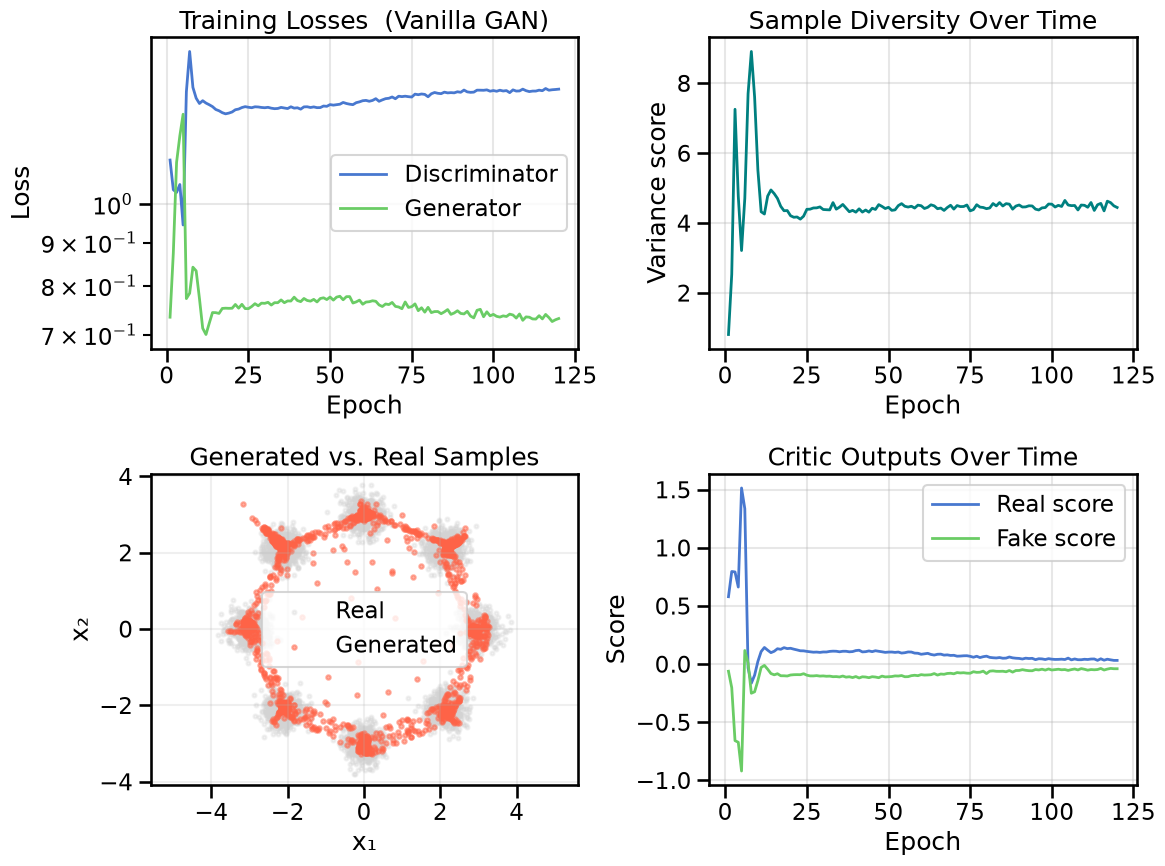

In [9]:
plot_model_diagnostics(H, X_ring, G, noise_dim=2, title_suffix=' (Vanilla GAN)')

In addition to the above training diagnostics, it can also be useful to plot interpolations in latent space to see how smoothly the Generator can move between different modes of the data distribution. In the case of a well-trained GAN, we would expect that interpolating between two points in latent space should produce a smooth transition in data space, moving through intermediate samples that also look realistic. In this case, this means hopping smoothly between the different Gaussian blobs in our ring-of-Gaussians dataset, and not jumping back-and-forth randomly between them.

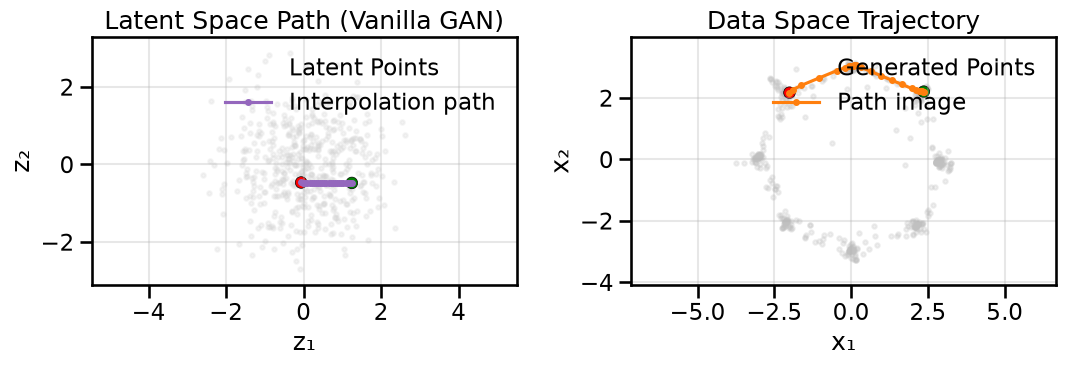

In [10]:
plot_latent_interpolation(G, noise_dim=2, title_suffix=' (Vanilla GAN)')

To give you some interactive control on visualizing the forward mapping $f(z) \rightarrow x$, use the sliders below to move a single latent vector (left-side plot) and observe the corresponding generated point in data space (right-side plot). By moving around in $z$ you can try to align the generated point with a particular mode on the ring. 

In [11]:
if interact is not None:
    def _move_latent(z1: float = 0.0, z2: float = 0.0):
        """
        Visualize the effect of moving a latent vector z = [z1, z2] through the generator.
        Left: latent space (z1, z2) with current point highlighted.
        Right: generated data point in data space, overlaid on the real data.
        """
        z = torch.tensor([[z1, z2]], dtype=torch.float32, device=device)
        with torch.no_grad():
            x = G(z).cpu().numpy()[0]

        fig, axes = plt.subplots(1, 2, figsize=(11, 5))

        # Left: latent space
        axes[0].scatter(0, 0, s=40, color='gray', alpha=0.2, label='Origin')
        axes[0].scatter(z1, z2, s=120, color='crimson', edgecolors='k', linewidths=0.5, label='Current z')
        axes[0].set_title('Latent Space (z)')
        axes[0].set_xlabel('z1')
        axes[0].set_ylabel('z2')
        axes[0].set_xlim(ring_latent_limits[0])
        axes[0].set_ylim(ring_latent_limits[1])
        axes[0].grid(True, alpha=0.3)
        axes[0].legend(loc='upper left', frameon=False)

        # Right: data space
        axes[1].scatter(X_ring[:,0], X_ring[:,1], s=10, alpha=0.15, color='gray', label='Real')
        axes[1].scatter([x[0]], [x[1]], s=120, color='crimson', edgecolors='k', linewidths=0.5, label='Generated')
        axes[1].set_title('Generated Data Point')
        axes[1].set_xlabel('x1')
        axes[1].set_ylabel('x2')
        axes[1].set_xlim(ring_data_limits[0])
        axes[1].set_ylim(ring_data_limits[1])
        axes[1].grid(True, alpha=0.3)
        axes[1].legend(loc='upper left', frameon=False)

        plt.tight_layout()
        plt.show()
    interact(
        _move_latent,
        z1=FloatSlider(min=-3.0, max=3.0, step=0.05, value=0.0, description='z1'),
        z2=FloatSlider(min=-3.0, max=3.0, step=0.05, value=0.0, description='z2'),
    )
else:
    print('ipywidgets not available; skipping latent sliders.')

interactive(children=(FloatSlider(value=0.0, description='z1', max=3.0, min=-3.0, step=0.05), FloatSlider(valu…

## What the Discriminator Looks Like

What you will notice from the above code is that the generator isn't really concerned with where the actual data is located. We can see this by noticing that in either loss formulation it only ever depends on $\mathbb{E}_{z \sim p_{(z)}}$, and never on $\mathbb{E}_{x \sim p_{\text{data}}(x)}$. Because of this, no gradients for the generator actually depend directly on the input data, and the only gradients that affect the generator come from its interplay with the discriminator! Look at the training loop again: `xb` only enters the discriminator step. The only thing that reaches the generator is the gradient of its loss, $\mathcal{L}_G = -\log \sigma(\ell(G(z)))$, where $\ell(G(z))$ is the discriminator's logit at $G(z)$. That gradient flows back through the discriminator into each fake sample. So to gain a better understanding of what the generator learns, we can look at the discriminator's logit as a map over the whole data space.

What would a perfect discriminator draw on that map? For a fixed generator with sample density $p_G$, the discriminator that maximizes $V(D, G)$ is

$$
D^*(x) = \frac{p_{\text{data}}(x)}{p_{\text{data}}(x) + p_G(x)}, \qquad \ell^*(x) = \log p_{\text{data}}(x) - \log p_G(x).
$$

The logit is positive where the data have more mass than the generator and negative where the generator puts too much mass. Each fake sample moves in the direction of $-\nabla_x \mathcal{L}_G = (1 - \sigma(\ell))\, \nabla_x \ell$: essentially trying to move samples such that they increase in probability w.r.t the discriminator's logit. Below we draw the logit as a color map (red is higher likelihood of the discriminator thinking the point is real, blue is where the discriminator thinks the point might be fake, and the black line is $\ell = 0$), the real data is shown in gray, the generator's samples are shown in orange, and optionally the green arrow shows the direction each generated sample would move to "make it more realistic" with respect to the discriminator.

In [12]:
import copy

# A fixed set of latent vectors, so every map below shows the same generator samples
Z_SHOW = torch.randn(500, 2, generator=torch.Generator().manual_seed(RNG_SEED)).to(device)


def generator_push(D_net, x_fake):
    # Direction that lowers the generator loss -log(sigmoid(logit)) at each fake sample
    x = x_fake.clone().requires_grad_(True)
    loss_g = nn.functional.binary_cross_entropy_with_logits(D_net(x), torch.ones(len(x), device=device), reduction='sum')
    loss_g.backward()
    return -x.grad


def plot_discriminator_map(D_net, G_net, ax=None, arrows=False, n_arrows=150, lim=None, title='', X_real=None):
    # D's logit over the data space, the real data (the ring unless X_real is given),
    # the generator's samples and (optionally) their push
    if X_real is None:
        X_real = X_ring
    if ax is None:
        fig, ax = plt.subplots(figsize=(6.5, 5.5))
    with torch.no_grad():
        x_fake = G_net(Z_SHOW)
    fake_np = x_fake.cpu().numpy()
    if lim is None:
        # Show at least [-5, 5] x [-5, 5], and widen the window if the generator's samples lie outside it
        lim = max(5.0, 1.1 * np.percentile(np.abs(fake_np).max(axis=1), 99))
    grid_1d = np.linspace(-lim, lim, 201)
    xx, yy = np.meshgrid(grid_1d, grid_1d)
    grid = torch.tensor(np.stack([xx.ravel(), yy.ravel()], axis=1), dtype=torch.float32, device=device)
    with torch.no_grad():
        logit = D_net(grid).cpu().numpy().reshape(xx.shape)
    v = np.abs(logit).max()
    im = ax.contourf(xx, yy, logit, levels=np.linspace(-v, v, 31), cmap='RdBu_r')
    ax.contour(xx, yy, logit, levels=[0], colors='k', linewidths=0.8)
    ax.scatter(X_real[:800, 0], X_real[:800, 1], s=4, color='0.35', alpha=0.4, label='Real')
    ax.scatter(fake_np[:, 0], fake_np[:, 1], s=6, color='tab:orange', label='Generated')
    if arrows:
        push = generator_push(D_net, x_fake[:n_arrows]).cpu().numpy()
        # The longest arrow is 16% of the window's half-width; only directions and relative lengths matter
        ax.quiver(fake_np[:n_arrows, 0], fake_np[:n_arrows, 1], push[:, 0], push[:, 1], color='darkgreen',
                  angles='xy', scale_units='xy', scale=np.linalg.norm(push, axis=1).max() / (0.16 * lim), width=0.004)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect('equal')
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.set_title(title, fontsize=11)
    plt.colorbar(im, ax=ax, fraction=0.046, label='Discriminator logit')
    return ax

Let's look at the map early in training, when the generator is still bad. The cell below trains a fresh generator and discriminator for only 2 epochs with the chapter's settings and keeps them as `G_snap` and `D_snap` (the chapter's `G` and `D` stay as they are).

Epoch 001/2 | D 1.128 | G 0.734 | Div 0.809
Epoch 002/2 | D 1.040 | G 0.874 | Div 2.533


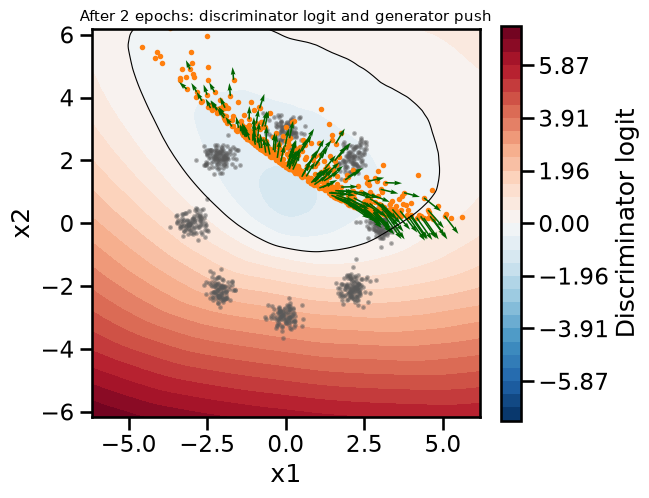

In [13]:
torch.manual_seed(RNG_SEED)
G_snap, D_snap, H_snap = train_vanilla_gan(X_ring, epochs=2, batch_size=256, lr_g=2e-4, lr_d=2e-4,
                                           hidden_dim=256, noise_dim=2, print_every=1)
plot_discriminator_map(D_snap, G_snap, arrows=True, title='After 2 epochs: discriminator logit and generator push')
plt.tight_layout()
plt.show()

After two epochs the generator's samples lie on an arc across the upper half of the ring, and the discriminator's logit is negative (blue) around them. The logit is largest at the bottom left, where five of the eight modes have real data but no samples. Yet the green arrows do not point there, and many of them do not point at the nearest real cluster either. They point up the local slope of the logit. Along most of the arc that is upward and to the right, out of the blue basin over its nearest rim; at the right end of the arc it is down and to the right. The generator only uses the slope of the logit where it generated samples, and thus cannot see that there is a much higher slope toward the lower left corner.

In the training loop the two players take turns: one discriminator step, then one generator step. The function below continues training from the snapshot with only one player, or with both in turns, for a given number of steps. It works on copies, so `G_snap` and `D_snap` stay as they are.

In [14]:
def train_players(G_start, D_start, player='alternate', steps=200, batch_size=256, lr=2e-4, seed=RNG_SEED):
    # Continue training copies of (G_start, D_start): 'G only', 'D only' or 'alternate' (D step, then G step)
    torch.manual_seed(seed)
    G_new, D_new = copy.deepcopy(G_start), copy.deepcopy(D_start)
    opt_g = optim.Adam(G_new.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_d = optim.Adam(D_new.parameters(), lr=lr, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    X_t = torch.from_numpy(X_ring).to(device)
    ones = torch.ones(batch_size, device=device)
    zeros = torch.zeros(batch_size, device=device)
    for step in range(steps):
        if player in ('D only', 'alternate'):
            xb = X_t[torch.randint(0, len(X_t), (batch_size,), device=device)]
            with torch.no_grad():
                x_fake = G_new(torch.randn(batch_size, 2, device=device))
            opt_d.zero_grad()
            loss_d = bce(D_new(xb), ones) + bce(D_new(x_fake), zeros)
            loss_d.backward()
            opt_d.step()
        if player in ('G only', 'alternate'):
            opt_g.zero_grad()
            loss_g = bce(D_new(G_new(torch.randn(batch_size, 2, device=device))), ones)
            loss_g.backward()
            opt_g.step()
    return G_new, D_new

Use the controls below to choose which player trains and for how many steps, starting from the snapshot. The default trains both players in turns for 200 steps, as the chapter's loop does.

In [15]:
from ipywidgets import interact, Dropdown, IntSlider, Checkbox


def show_players(player='alternate', steps=200, arrows=False):
    G_new, D_new = train_players(G_snap, D_snap, player=player, steps=steps)
    plot_discriminator_map(D_new, G_new, arrows=arrows, title=f'From the snapshot: {player}, {steps} steps',
                           lim=6)
    plt.tight_layout()
    plt.show()


interact(show_players,
         player=Dropdown(options=['alternate', 'G only', 'D only'], value='alternate', description='Train'),
         steps=IntSlider(min=0, max=200, step=1, value=200, description='Steps', continuous_update=False),
         arrows=Checkbox(value=False, description='Arrows'))

interactive(children=(Dropdown(description='Train', options=('alternate', 'G only', 'D only'), value='alternat…

<function __main__.show_players(player='alternate', steps=200, arrows=False)>

With both players taking turns, the samples spread over the ring within 200 steps, and the logit shrinks to within about $\pm 1$ (look at the color bar). Try the other two settings and different numbers of steps. What happens when only one of the two players learns?

## Conditional Generation Examples

So far, we've explored unconditional generative models that learn to produce samples from the overall data distribution. However, in many practical applications, we want to control what we generate by conditioning on additional information. For example, we might want to generate samples from a specific mode of the distribution, or generate samples with particular properties.

In this section, we'll explore two types of conditioning:

1. **Discrete Conditioning (One-Hot Mode Index):** Condition the GAN on which Gaussian mode in our ring dataset the sample should come from.
2. **Continuous Conditioning (Radius):** Condition the GAN on a continuous scalar representing the radius from the origin.

These conditioning strategies are widely applicable and form the basis for more complex conditional generation tasks, such as class-conditional image generation or text-to-image synthesis.

### Conditional Example A — One-Hot Mode Conditioning

In this example, we'll condition the GAN on which of the 8 Gaussian modes in the ring dataset we want to generate from. We provide a one-hot encoded vector indicating the target mode to both the generator and discriminator.

The key idea is simple: we concatenate the one-hot label to the inputs of both networks. The generator receives both random noise $z$ and the label $y$, learning to map $(z, y) \rightarrow x$. The discriminator receives both the data point $x$ and the label $y$, learning to distinguish real pairs $(x, y)$ from fake pairs $(G(z, y), y)$.

In [16]:
#| code-fold: false
# Conditional Generator: takes noise + one-hot label
class ConditionalMLPGenerator(nn.Module):
    def __init__(self, noise_dim: int = 2, label_dim: int = 8, hidden_dim: int = 256, out_dim: int = 2):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(noise_dim + label_dim, hidden_dim), nn.LeakyReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.LeakyReLU(),
            nn.Linear(hidden_dim, out_dim),
        )
    def forward(self, z: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
        # Concatenate noise and label
        zy = torch.cat([z, y], dim=1)
        return self.main(zy)

# Conditional Discriminator: takes data + one-hot label
class ConditionalMLPDiscriminator(nn.Module):
    def __init__(self, input_dim: int = 2, label_dim: int = 8, hidden_dim: int = 256):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(input_dim + label_dim, hidden_dim), nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, hidden_dim), nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, 1),
        )
    def forward(self, x: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
        xy = torch.cat([x, y], dim=1)
        return self.main(xy).squeeze(-1)

def train_conditional_gan_onehot(
    data: np.ndarray, labels: np.ndarray, n_classes: int = 8, *,
    noise_dim: int = 2, batch_size: int = 256, epochs: int = 120,
    lr_g: float = 2e-4, lr_d: float = 2e-4, hidden_dim: int = 256, print_every: int = 40
) -> tuple[nn.Module, nn.Module, GanHistory]:
    loader = make_conditional_loader_onehot(data, labels, batch_size, n_classes)
    G = ConditionalMLPGenerator(noise_dim=noise_dim, label_dim=n_classes, hidden_dim=hidden_dim).to(device)
    D = ConditionalMLPDiscriminator(input_dim=2, label_dim=n_classes, hidden_dim=hidden_dim).to(device)
    opt_g = optim.Adam(G.parameters(), lr=lr_g, betas=(0.5, 0.999))
    opt_d = optim.Adam(D.parameters(), lr=lr_d, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    hist = GanHistory([], [], [], [], [])

    for ep in range(epochs):
        d_losses, g_losses, real_scores, fake_scores = [], [], [], []
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            # Discriminator step
            z = torch.randn(xb.size(0), noise_dim, device=device)
            with torch.no_grad():
                x_fake = G(z, yb)
            opt_d.zero_grad()
            d_real = D(xb, yb)
            d_fake = D(x_fake, yb)
            loss_d = bce(d_real, torch.ones_like(d_real)) + bce(d_fake, torch.zeros_like(d_fake))
            loss_d.backward()
            opt_d.step()
            d_losses.append(float(loss_d.detach().cpu().item()))
            real_scores.append(d_real.mean().item())
            fake_scores.append(d_fake.mean().item())

            # Generator step
            z = torch.randn(xb.size(0), noise_dim, device=device)
            opt_g.zero_grad()
            xg = G(z, yb)
            dg = D(xg, yb)
            loss_g = bce(dg, torch.ones_like(dg))
            loss_g.backward()
            opt_g.step()
            g_losses.append(float(loss_g.detach().cpu().item()))
        
        with torch.no_grad():
            z_eval = torch.randn(2048, noise_dim, device=device)
            y_eval = torch.nn.functional.one_hot(
                torch.randint(0, n_classes, (2048,), device=device), num_classes=n_classes
            ).to(torch.float32)
            samples = G(z_eval, y_eval)
            div = compute_diversity_metric(samples)

        hist.d_loss.append(float(np.mean(d_losses)))
        hist.g_loss.append(float(np.mean(g_losses)))
        hist.diversity.append(div)
        hist.real_scores.append(float(np.mean(real_scores)))
        hist.fake_scores.append(float(np.mean(fake_scores)))
        if (ep+1) % max(1, print_every) == 0 or ep==0:
            print(f"Epoch {ep+1:03d}/{epochs} | D {hist.d_loss[-1]:.3f} | G {hist.g_loss[-1]:.3f} | Div {div:.3f}")
    return G, D, hist

# Train the conditional GAN
G_cond_onehot, D_cond_onehot, H_cond_onehot = train_conditional_gan_onehot(
    X_ring, y_ring, n_classes=8, epochs=480, batch_size=256, 
    lr_g=2e-4, lr_d=2e-4, hidden_dim=256, noise_dim=2, print_every=40
)

Epoch 001/480 | D 1.272 | G 0.720 | Div 0.018
Epoch 040/480 | D 1.403 | G 0.692 | Div 4.806
Epoch 080/480 | D 1.387 | G 0.691 | Div 4.508
Epoch 120/480 | D 1.387 | G 0.694 | Div 4.579
Epoch 160/480 | D 1.382 | G 0.682 | Div 4.723
Epoch 200/480 | D 1.393 | G 0.672 | Div 4.008
Epoch 240/480 | D 1.385 | G 0.705 | Div 4.374
Epoch 280/480 | D 1.389 | G 0.711 | Div 4.745
Epoch 320/480 | D 1.388 | G 0.683 | Div 4.019
Epoch 360/480 | D 1.385 | G 0.691 | Div 4.852
Epoch 400/480 | D 1.384 | G 0.690 | Div 4.930
Epoch 440/480 | D 1.388 | G 0.697 | Div 4.347
Epoch 480/480 | D 1.388 | G 0.688 | Div 4.380


Now let's visualize the conditional samples. We'll generate samples for each of the 8 modes and plot them to see if the generator has learned to respect the conditioning signal.

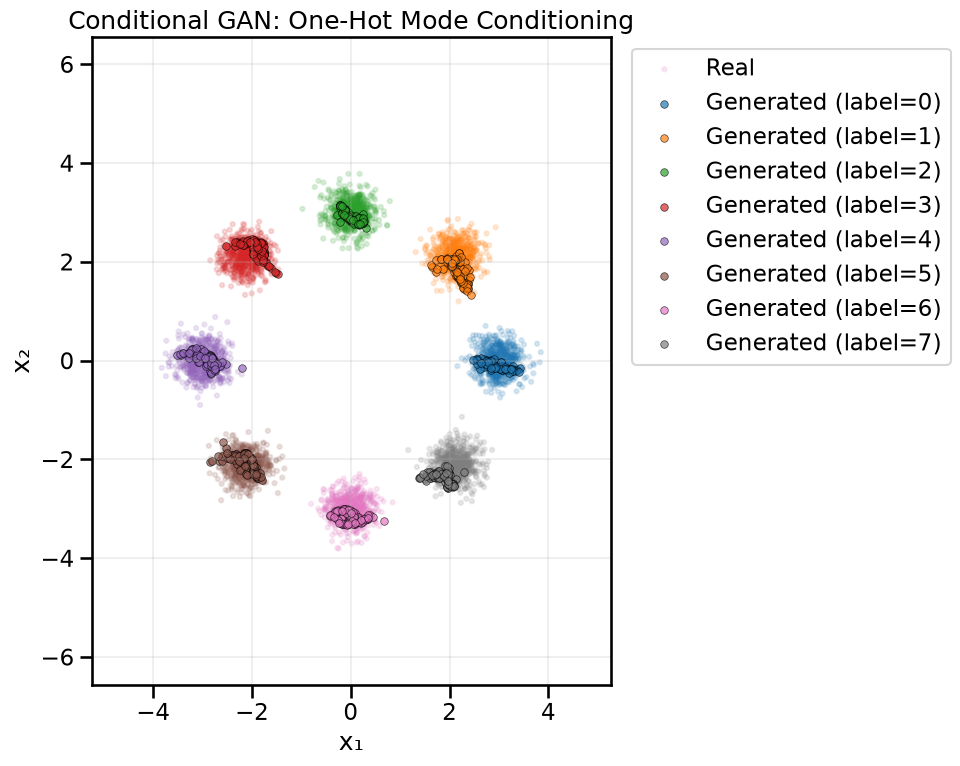

In [17]:
# Generate conditional samples for each mode
G_cond_onehot.eval()
samples_by_label = {}
n_samples_per_mode = 100

for label in range(8):
    z = torch.randn(n_samples_per_mode, 2, device=device)
    y = torch.nn.functional.one_hot(
        torch.full((n_samples_per_mode,), label, device=device), num_classes=8
    ).to(torch.float32)
    with torch.no_grad():
        samples = G_cond_onehot(z, y).cpu().numpy()
    samples_by_label[label] = samples

plot_conditional_samples_discrete(
    samples_by_label, X_ring, y_ring, title="Conditional GAN: One-Hot Mode Conditioning"
)

### Conditional Example B — Continuous Radius Conditioning

Instead of conditioning on discrete labels, we can also condition on continuous scalar values. In this example, we'll condition the GAN on the radius (distance from the origin) of the generated samples. This allows us to control how far from the origin samples are generated.

To handle continuous conditioning, we typically embed the scalar through a small MLP before concatenating it with other inputs. This gives the network more flexibility in how it uses the conditioning signal.

In [18]:
#| code-fold: false
from gen_models_utilities import make_conditional_loader_radius, plot_conditional_samples_continuous

# Conditional Generator with radius embedding
class ConditionalMLPGeneratorRadius(nn.Module):
    def __init__(self, noise_dim: int = 2, cond_emb_dim: int = 16, hidden_dim: int = 256, out_dim: int = 2):
        super().__init__()
        # Embed the scalar radius into a higher-dimensional space
        self.cond_embed = nn.Sequential(
            nn.Linear(1, cond_emb_dim),
            nn.LeakyReLU(),
            nn.Linear(cond_emb_dim, cond_emb_dim),
        )
        self.main = nn.Sequential(
            nn.Linear(noise_dim + cond_emb_dim, hidden_dim), nn.LeakyReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.LeakyReLU(),
            nn.Linear(hidden_dim, out_dim),
        )
    def forward(self, z: torch.Tensor, r: torch.Tensor) -> torch.Tensor:
        r_emb = self.cond_embed(r)
        zr = torch.cat([z, r_emb], dim=1)
        return self.main(zr)

# Conditional Discriminator with radius embedding
class ConditionalMLPDiscriminatorRadius(nn.Module):
    def __init__(self, input_dim: int = 2, cond_emb_dim: int = 16, hidden_dim: int = 256):
        super().__init__()
        self.cond_embed = nn.Sequential(
            nn.Linear(1, cond_emb_dim),
            nn.LeakyReLU(),
            nn.Linear(cond_emb_dim, cond_emb_dim),
        )
        self.main = nn.Sequential(
            nn.Linear(input_dim + cond_emb_dim, hidden_dim), nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, hidden_dim), nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, 1),
        )
    def forward(self, x: torch.Tensor, r: torch.Tensor) -> torch.Tensor:
        r_emb = self.cond_embed(r)
        xr = torch.cat([x, r_emb], dim=1)
        return self.main(xr).squeeze(-1)

def train_conditional_gan_radius(
    data: np.ndarray, *,
    noise_dim: int = 2, batch_size: int = 256, epochs: int = 120,
    lr_g: float = 2e-4, lr_d: float = 2e-4, hidden_dim: int = 256, print_every: int = 40
) -> tuple[nn.Module, nn.Module, GanHistory]:
    loader = make_conditional_loader_radius(data, batch_size)
    # Radii of the real data points, used to draw realistic conditioning values for evaluation
    data_radii = torch.norm(torch.from_numpy(data).to(torch.float32), dim=1, keepdim=True).to(device)
    G = ConditionalMLPGeneratorRadius(noise_dim=noise_dim, hidden_dim=hidden_dim).to(device)
    D = ConditionalMLPDiscriminatorRadius(input_dim=2, hidden_dim=hidden_dim).to(device)
    opt_g = optim.Adam(G.parameters(), lr=lr_g, betas=(0.5, 0.999))
    opt_d = optim.Adam(D.parameters(), lr=lr_d, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    hist = GanHistory([], [], [], [], [])

    for ep in range(epochs):
        d_losses, g_losses, real_scores, fake_scores = [], [], [], []
        for xb, rb in loader:
            xb, rb = xb.to(device), rb.to(device)
            # Discriminator step
            z = torch.randn(xb.size(0), noise_dim, device=device)
            with torch.no_grad():
                x_fake = G(z, rb)
            opt_d.zero_grad()
            d_real = D(xb, rb)
            d_fake = D(x_fake, rb)
            loss_d = bce(d_real, torch.ones_like(d_real)) + bce(d_fake, torch.zeros_like(d_fake))
            loss_d.backward()
            opt_d.step()
            d_losses.append(float(loss_d.detach().cpu().item()))
            real_scores.append(d_real.mean().item())
            fake_scores.append(d_fake.mean().item())

            # Generator step
            z = torch.randn(xb.size(0), noise_dim, device=device)
            opt_g.zero_grad()
            xg = G(z, rb)
            dg = D(xg, rb)
            loss_g = bce(dg, torch.ones_like(dg))
            loss_g.backward()
            opt_g.step()
            g_losses.append(float(loss_g.detach().cpu().item()))
        
        with torch.no_grad():
            z_eval = torch.randn(2048, noise_dim, device=device)
            r_eval = data_radii[torch.randint(0, data_radii.size(0), (2048,), device=device)]
            samples = G(z_eval, r_eval)
            div = compute_diversity_metric(samples)

        hist.d_loss.append(float(np.mean(d_losses)))
        hist.g_loss.append(float(np.mean(g_losses)))
        hist.diversity.append(div)
        hist.real_scores.append(float(np.mean(real_scores)))
        hist.fake_scores.append(float(np.mean(fake_scores)))
        if (ep+1) % max(1, print_every) == 0 or ep==0:
            print(f"Epoch {ep+1:03d}/{epochs} | D {hist.d_loss[-1]:.3f} | G {hist.g_loss[-1]:.3f} | Div {div:.3f}")
    return G, D, hist

# Train the conditional GAN with radius conditioning
G_cond_radius, D_cond_radius, H_cond_radius = train_conditional_gan_radius(
    X_ring, epochs=480, batch_size=256, 
    lr_g=2e-4, lr_d=2e-4, hidden_dim=256, noise_dim=2, print_every=40
)

Epoch 001/480 | D 1.271 | G 0.751 | Div 0.014
Epoch 040/480 | D 1.287 | G 0.766 | Div 4.688
Epoch 080/480 | D 1.288 | G 0.767 | Div 4.356
Epoch 120/480 | D 1.306 | G 0.772 | Div 4.473
Epoch 160/480 | D 1.335 | G 0.758 | Div 4.527
Epoch 200/480 | D 1.352 | G 0.745 | Div 4.411
Epoch 240/480 | D 1.361 | G 0.734 | Div 4.652
Epoch 280/480 | D 1.364 | G 0.728 | Div 4.435
Epoch 320/480 | D 1.365 | G 0.721 | Div 4.446
Epoch 360/480 | D 1.365 | G 0.728 | Div 4.633
Epoch 400/480 | D 1.364 | G 0.733 | Div 4.670
Epoch 440/480 | D 1.366 | G 0.722 | Div 4.713
Epoch 480/480 | D 1.366 | G 0.730 | Div 4.461


Now let's generate samples at different radius values to see how the generator responds to continuous conditioning. We'll sweep through several radius values and visualize the results.

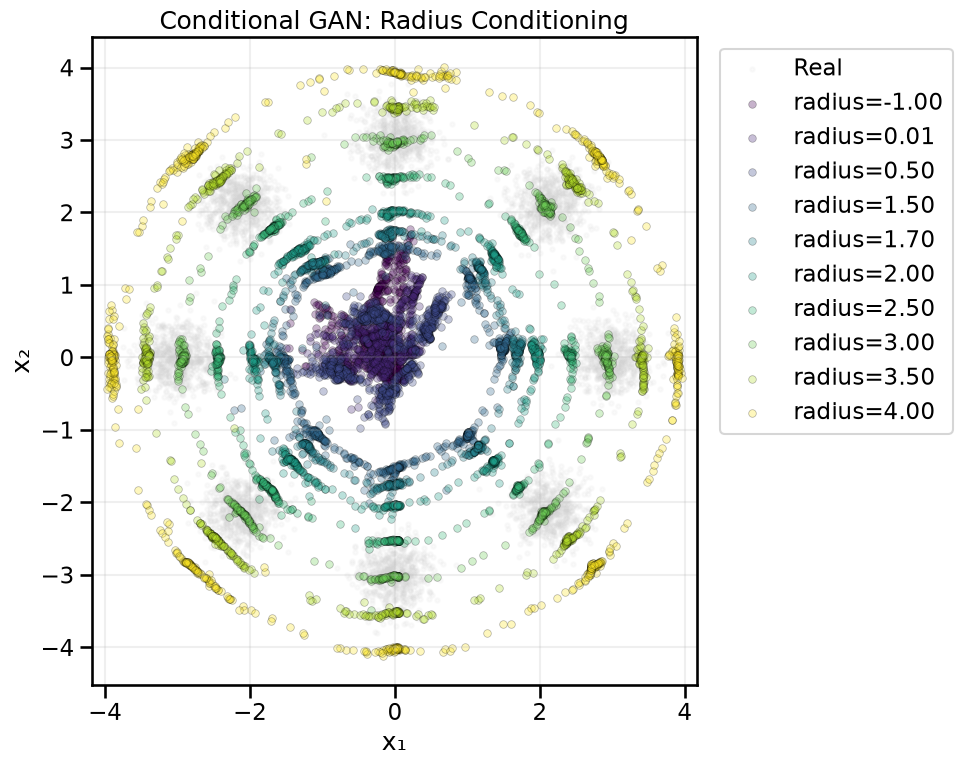

In [19]:
# Generate conditional samples for different radius values
G_cond_radius.eval()
samples_by_radius = {}
n_samples_per_radius = 800
radius_values = [-1.0 , 0.01, 0.5, 1.5, 1.7, 2.0, 2.5, 3.0, 3.5, 4.0]

for r_val in radius_values:
    z = torch.randn(n_samples_per_radius, 2, device=device)
    r = torch.full((n_samples_per_radius, 1), r_val, device=device)
    with torch.no_grad():
        samples = G_cond_radius(z, r).cpu().numpy()
    samples_by_radius[r_val] = samples

plot_conditional_samples_continuous(
    samples_by_radius, X_ring, title="Conditional GAN: Radius Conditioning", value_name="radius"
)

## Summary and Next Steps

OK, so we have seen how a basic GAN is set up and trained, and covered some diagnostic plots that give us insight into how the training went. This gave us the following sets of useful tools:

- We could learn a forward mapping function $f(z) \rightarrow x$ that could push forward a given sample in $z$ to a corresponding sample in $x$. This could learn distributions that were far more complex than a simple linear map could achieve above. 
- This $f$ is a deterministic function -- i.e., the same $z$ will always produce the same $x$.
- We could produce latent interpolations in $z$ that produced smooth transitions in $x$ and seemed to capture the overall clustering behavior of certain distributions.

Unfortunately, GANs did not give us any of the following properties, which will turn out to be useful later and motivate other types of generative models:

- We did not learn an inverse mapping $f^{-1}(x) \rightarrow z$. This means that we cannot easily encode real data samples into the latent space, which would be useful for many applications. For example, if I wanted to slightly modify $x$ -- e.g., $x^\prime = x+\delta x$ -- and compute the corresponding latent coordinate $z^\prime = z+\delta z$, GANs do not provide a built-in mechanism to do this.[^gan-32-2] We will see how both Variational Autoencoders (VAEs) and Normalizing Flows (NFs) address this problem.
- We also cannot yet easily talk about or compute probability mappings between $p(x)$ and $p(z)$, which would be useful for computing likelihoods of data samples or for evaluating how well the model fits the data distribution, both of which are quite useful. Again, we will see later how both VAEs and NFs address this problem.

Before we move beyond GANs, however, we will first explore some of the complex training dynamics and other subtle issues that arise when applying them in practice. This will help you build up your intuition and experience in how to assess problems in generative models and will serve as a strong basis upon which to launch into more complex models later. It will also give us an opportunity to introduce the concept of **Optimal Transport**, which will be useful in its own right later on, and will also help us understand some of the limitations of GANs should you encounter their use in the future.

[^gan-32-2]: Of course, I could try to get at this another way, for example, by applying automatic differentiation to the Generator to compute $\frac{\partial f}{\partial z}$ and then use that to estimate $\delta z \approx (\frac{\partial f}{\partial z})^{-1} \delta x$, but this requires extra work on our part and this is not always straightforward, especially if the Jacobian is ill-conditioned.

## Exercises

The exercises reuse the chapter's data, networks and training code, so run the chapter's cells first. Rough time estimates are in the titles.

Exercise 1 uses a new data set, two moons, and follows single updates of the two networks. The cell below scales the two-moons data set from scikit-learn to about the size of the ring and trains the chapter's GAN on it with `train_vanilla_gan` for only 3 epochs. Run it to produce three figures, all drawn with `plot_discriminator_map`:

1. The discriminator's logit and the generator's samples after these 3 epochs.
2. Panels A to D, which put an arrow on 80 of these samples to demonstrate the direction the generated sample would move. 
3. The same discriminator again, and three candidate discriminators, A to C. Each candidate starts from that discriminator and takes a short burst of 25 discriminator steps.

Every map has its own color scale.

Epoch 001/3 | D 1.261 | G 0.728 | Div 0.621
Epoch 003/3 | D 1.467 | G 0.805 | Div 2.755
Epoch 001/5 | D 1.261 | G 0.728 | Div 0.621
Epoch 005/5 | D 1.465 | G 0.791 | Div 1.170


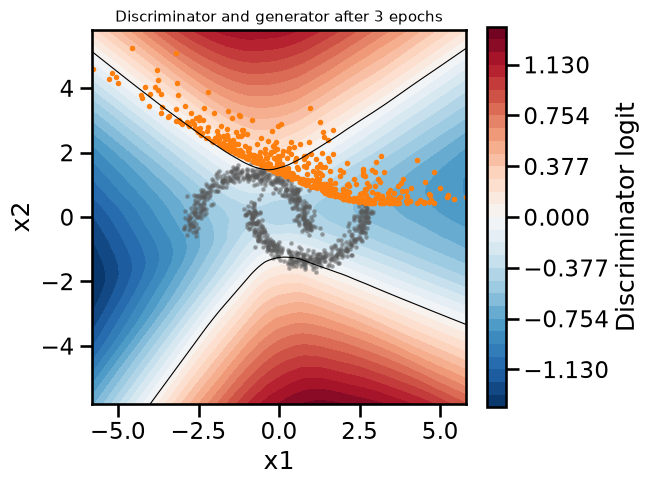

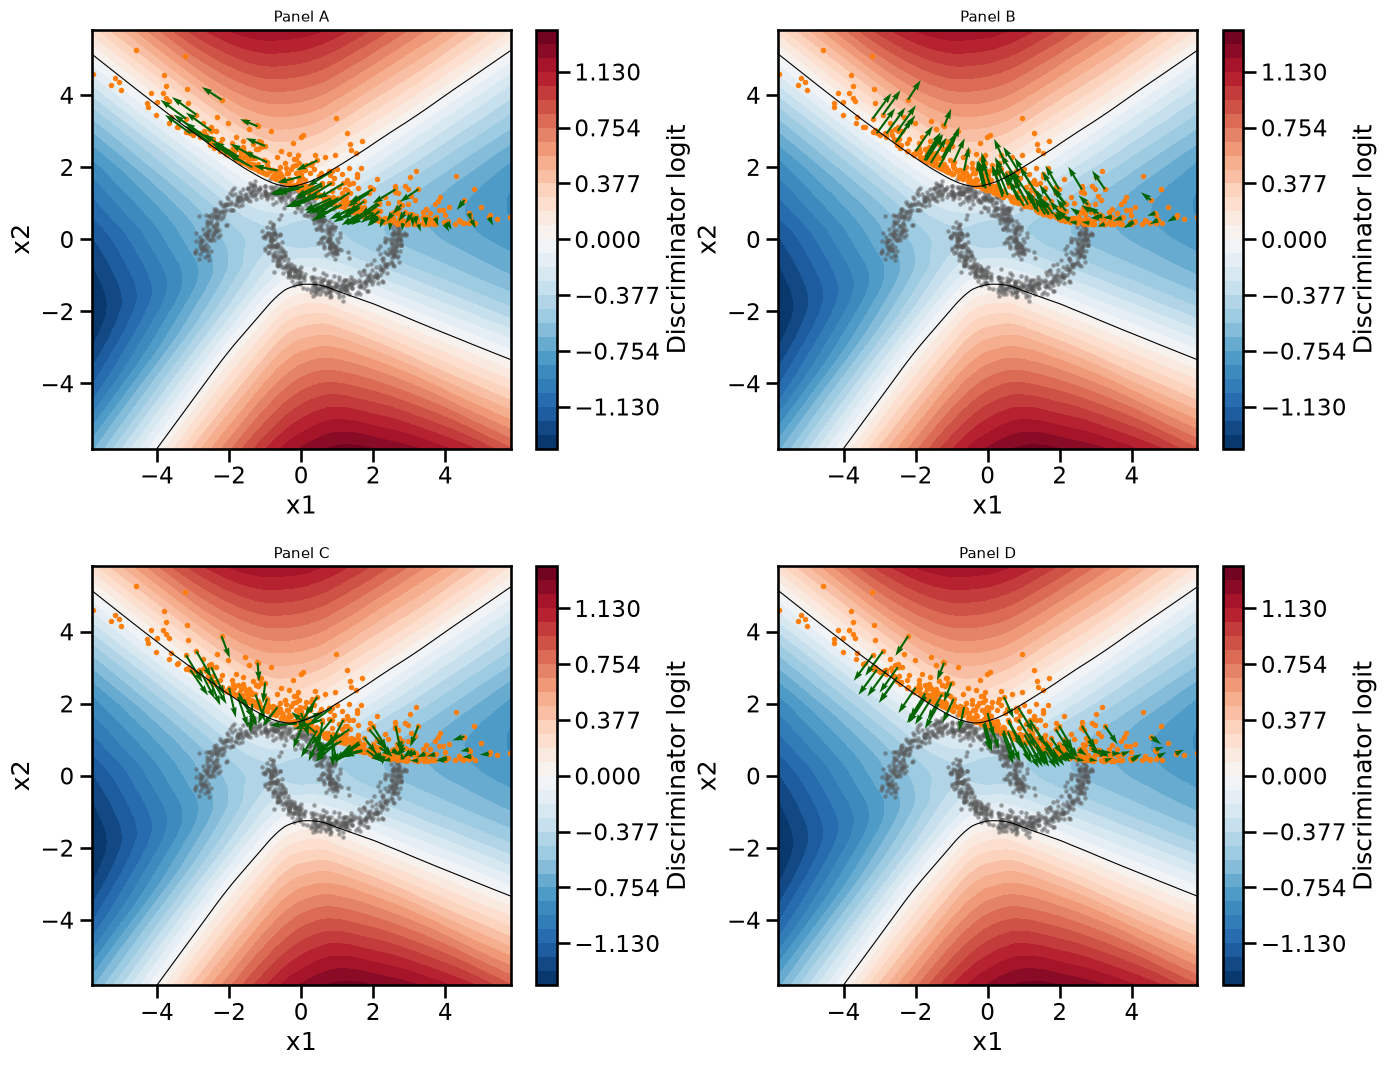

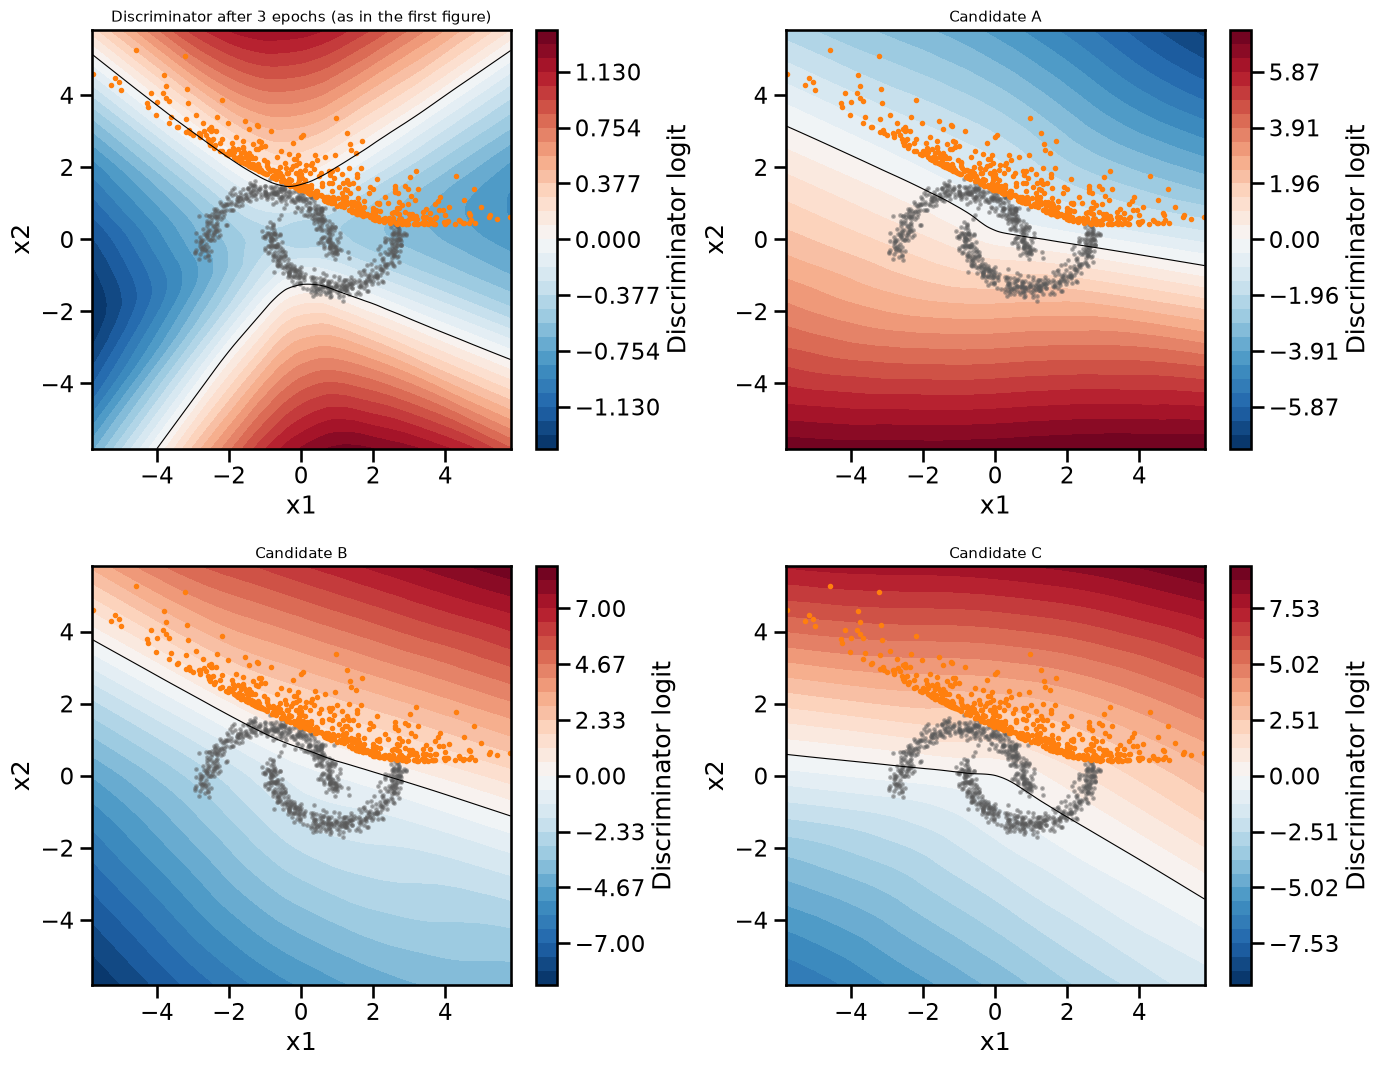

In [20]:
#| echo: false
# Figures for Exercise 1: the chapter's GAN after 3 epochs on two moons, four arrow fields, three candidate discriminators
from sklearn.datasets import make_moons

EX1_EPOCHS = 3        # the snapshot shown in the figures
EX1_LATER_EPOCHS = 5  # the same run two epochs later (its samples train one of the candidates)
EX1_D_STEPS = 25      # discriminator steps from the snapshot for the candidates
EX1_ARROWS = 80       # samples that get an arrow

X_moons, _ = make_moons(5000, noise=0.08, random_state=RNG_SEED)
X_moons = (1.8 * (X_moons - X_moons.mean(axis=0))).astype(np.float32)

torch.manual_seed(RNG_SEED)
G_moons, D_moons, _ = train_vanilla_gan(X_moons, epochs=EX1_EPOCHS, print_every=EX1_EPOCHS)
torch.manual_seed(RNG_SEED)
G_moons_later, _, _ = train_vanilla_gan(X_moons, epochs=EX1_LATER_EPOCHS, print_every=EX1_LATER_EPOCHS)


def train_discriminator(D_start, G_net, steps, swap_labels=False, batch_size=256, lr=2e-4, seed=RNG_SEED):
    # Discriminator steps as in the chapter's loop, on a copy of D_start, against samples of a frozen G_net
    torch.manual_seed(seed)
    D_new = copy.deepcopy(D_start)
    opt_d = optim.Adam(D_new.parameters(), lr=lr, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    X_t = torch.from_numpy(X_moons).to(device)
    real_label, fake_label = (0.0, 1.0) if swap_labels else (1.0, 0.0)
    for step in range(steps):
        xb = X_t[torch.randint(0, len(X_t), (batch_size,), device=device)]
        with torch.no_grad():
            x_fake = G_net(torch.randn(batch_size, 2, device=device))
        opt_d.zero_grad()
        loss_d = (bce(D_new(xb), torch.full((batch_size,), real_label, device=device))
                  + bce(D_new(x_fake), torch.full((batch_size,), fake_label, device=device)))
        loss_d.backward()
        opt_d.step()
    return D_new


# Four arrow fields on the same samples, all with the length of the true push
with torch.no_grad():
    x_show = G_moons(Z_SHOW)
fake_np = x_show.cpu().numpy()
lim_moons = max(5.0, 1.1 * np.percentile(np.abs(fake_np).max(axis=1), 99))
push = generator_push(D_moons, x_show[:EX1_ARROWS]).cpu().numpy()
push_len = np.linalg.norm(push, axis=1, keepdims=True)
X_moons_t = torch.from_numpy(X_moons).to(device)
to_nearest = (X_moons_t[torch.cdist(x_show[:EX1_ARROWS], X_moons_t).argmin(dim=1)] - x_show[:EX1_ARROWS]).cpu().numpy()
arrow_fields = {'A': np.stack([-push[:, 1], push[:, 0]], axis=1),                         # along the contours
                'B': push,                                                               # true push
                'C': to_nearest / np.linalg.norm(to_nearest, axis=1, keepdims=True) * push_len,  # toward nearest real point
                'D': -push}                                                              # reversed

# The discriminator after EX1_EPOCHS epochs and the generator's samples
plot_discriminator_map(D_moons, G_moons, lim=lim_moons, X_real=X_moons,
                       title=f'Discriminator and generator after {EX1_EPOCHS} epochs')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (letter, field) in zip(axes.ravel(), arrow_fields.items()):
    plot_discriminator_map(D_moons, G_moons, ax=ax, lim=lim_moons, X_real=X_moons, title=f'Panel {letter}')
    ax.quiver(fake_np[:EX1_ARROWS, 0], fake_np[:EX1_ARROWS, 1], field[:, 0], field[:, 1], color='darkgreen',
              angles='xy', scale_units='xy', scale=push_len.max() / (0.16 * lim_moons), width=0.005)
plt.tight_layout()
plt.show()

# Three candidate discriminators after a short burst of discriminator steps from D_moons
candidates = {'A': train_discriminator(D_moons, G_moons, EX1_D_STEPS),                     # against the samples shown
              'B': train_discriminator(D_moons, G_moons, EX1_D_STEPS, swap_labels=True),   # real/fake labels swapped
              'C': train_discriminator(D_moons, G_moons_later, EX1_D_STEPS)}               # against another generator's samples
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
plot_discriminator_map(D_moons, G_moons, ax=axes[0, 0], lim=lim_moons, X_real=X_moons,
                       title=f'Discriminator after {EX1_EPOCHS} epochs (as in the first figure)')
for ax, (letter, D_cand) in zip(axes.ravel()[1:], candidates.items()):
    plot_discriminator_map(D_cand, G_moons, ax=ax, lim=lim_moons, X_real=X_moons, title=f'Candidate {letter}')
plt.tight_layout()
plt.show()

::: {.callout-note appearance="simple" icon=false}
### Exercise 1 (~5 min): One step at a time
In the chapter's training loop, each network takes one step at a time against the other network as it is at that moment.

- (a) Which panel of the second figure shows the direction in which each sample moves when the generator takes a step against the discriminator shown? Why? Why are the arrows longer in some places than in others?
- (b) Which candidate in the third figure is the discriminator after 25 more discriminator steps against the samples shown? Why do the other two not fit?
:::

In [21]:
# You can use this code cell for this exercise, if you like.

---

Run the cell below to produce the figure for Exercise 2. It draws seven sets of 2048 samples each on top of the ring data (gray). The four ring sets use the ring's own mode centers and spread; the Gaussian and the disk are centered at the origin; the last set comes from the chapter's trained `G`. The chapter's diversity score of each set, `compute_diversity_metric`, is printed in a collapsed box after the exercise.

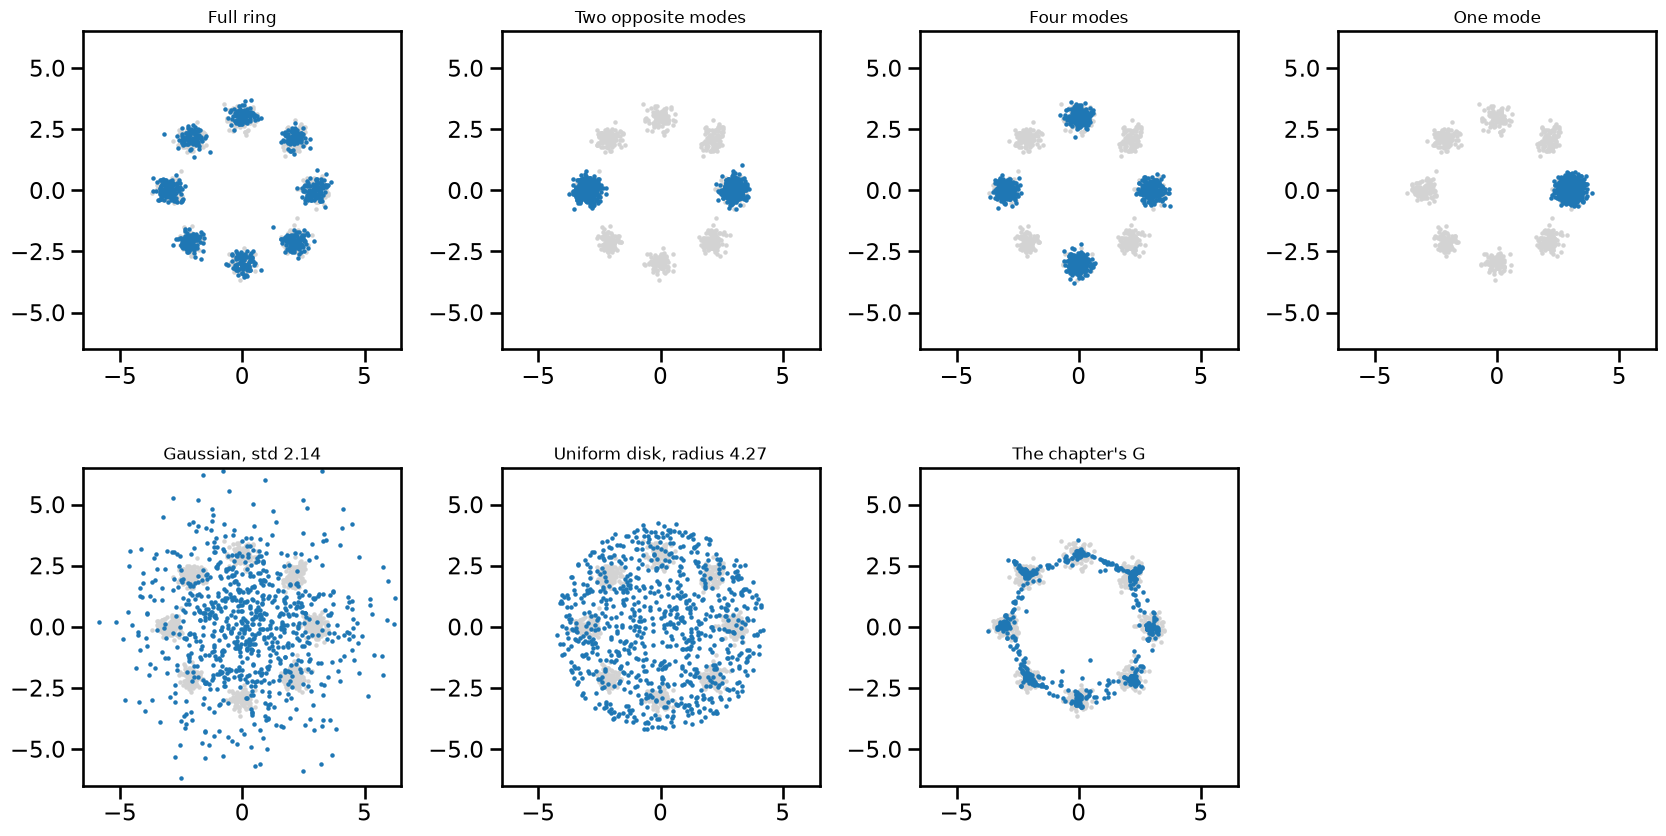

In [22]:
#| echo: false
# Figure for Exercise 2: seven sample sets of 2048 points (their diversity scores are printed further below)
rng_ex2 = np.random.default_rng(RNG_SEED)
n_ex2 = 2048
ring_angles = np.linspace(0, 2 * np.pi, 8, endpoint=False)
ring_centers = 3.0 * np.stack([np.cos(ring_angles), np.sin(ring_angles)], axis=1)


def ring_modes(modes):
    # Equal-weight Gaussian blobs (std 0.25) at the chosen mode centers of the ring
    pick = rng_ex2.choice(modes, n_ex2)
    return ring_centers[pick] + 0.25 * rng_ex2.standard_normal((n_ex2, 2))


disk_r = 4.272 * np.sqrt(rng_ex2.random(n_ex2))
disk_t = 2 * np.pi * rng_ex2.random(n_ex2)
torch.manual_seed(RNG_SEED)
with torch.no_grad():
    samples_G = G(torch.randn(n_ex2, 2, device=device)).cpu().numpy()

sample_sets = {
    'Full ring': ring_modes(np.arange(8)),
    'Two opposite modes': ring_modes([0, 4]),
    'Four modes': ring_modes([0, 2, 4, 6]),
    'One mode': ring_modes([0]),
    'Gaussian, std 2.14': 2.136 * rng_ex2.standard_normal((n_ex2, 2)),
    'Uniform disk, radius 4.27': np.stack([disk_r * np.cos(disk_t), disk_r * np.sin(disk_t)], axis=1),
    "The chapter's G": samples_G,
}
fig, axes = plt.subplots(2, 4, figsize=(17, 9))
for ax, (name, s) in zip(axes.ravel(), sample_sets.items()):
    ax.scatter(X_ring[:800, 0], X_ring[:800, 1], s=3, color='lightgray')
    ax.scatter(s[:800, 0], s[:800, 1], s=3, color='tab:blue')
    ax.set_title(name, fontsize=12)
    ax.set_xlim(-6.5, 6.5)
    ax.set_ylim(-6.5, 6.5)
    ax.set_aspect('equal')
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

::: {.callout-note appearance="simple" icon=false}
### Exercise 2 (~5 min): Seven generators, one score
The chapter tracks the diversity of the generated samples, the per-axis variance averaged over the two axes, as a check against mode collapse.

- (a) Before you open the scores below, rank the seven sets by how good a generator of the ring each would be, and predict their diversity scores. Why did you rank them that way?
- (b) Five very different sets score about 4.5. Why? What does the metric actually measure, and why does it come out nearly the same for 2, 4 and 8 ring modes?
- (c) The chapter's `G` scores below the Gaussian blob. Does that make it the worse generator? Why, and what would you need to look at instead?
:::

::: {.callout-tip collapse="true"}
### Diversity scores (open after you have made your predictions)

In [23]:
print(f"{'Sample set':28s} {'diversity':>9s}")
for name, s in sample_sets.items():
    print(f"{name:28s} {compute_diversity_metric(torch.from_numpy(np.asarray(s, dtype=np.float32))):9.2f}")

Sample set                   diversity
Full ring                         4.56
Two opposite modes                4.54
Four modes                        4.57
One mode                          0.06
Gaussian, std 2.14                4.69
Uniform disk, radius 4.27         4.58
The chapter's G                   4.42


:::

---

Exercise 3 moves from the ring to an engineering data set. Beams2D, from the EngiBench benchmark, contains beam designs optimized by topology optimization. Each design is a $50 \times 100$ grid of material densities between 0 (void) and 1 (solid). It is the right half of a symmetric, simply supported beam: the left edge is the symmetry line, a roller supports the bottom-right corner, and a downward load acts on the top edge at the red triangle. Each design minimizes the compliance (how much the beam deflects under its load, so lower is stiffer) for four conditions: the target volume fraction (the share of the grid filled with material), the minimum feature size `rmin`, the load position `forcedist` (0 at the left edge, 1 at the right) and an overhang flag.

The cell below loads a conditional GAN generator, `CGANGenerator` from `engibench_gen_models.py`, that was trained on the Beams2D training designs. It takes the four conditions and 32 noise values and returns a design. For three rows of the validation set, which the generator never saw, the cell draws the dataset's optimal design next to three generated designs, each from a different noise vector.

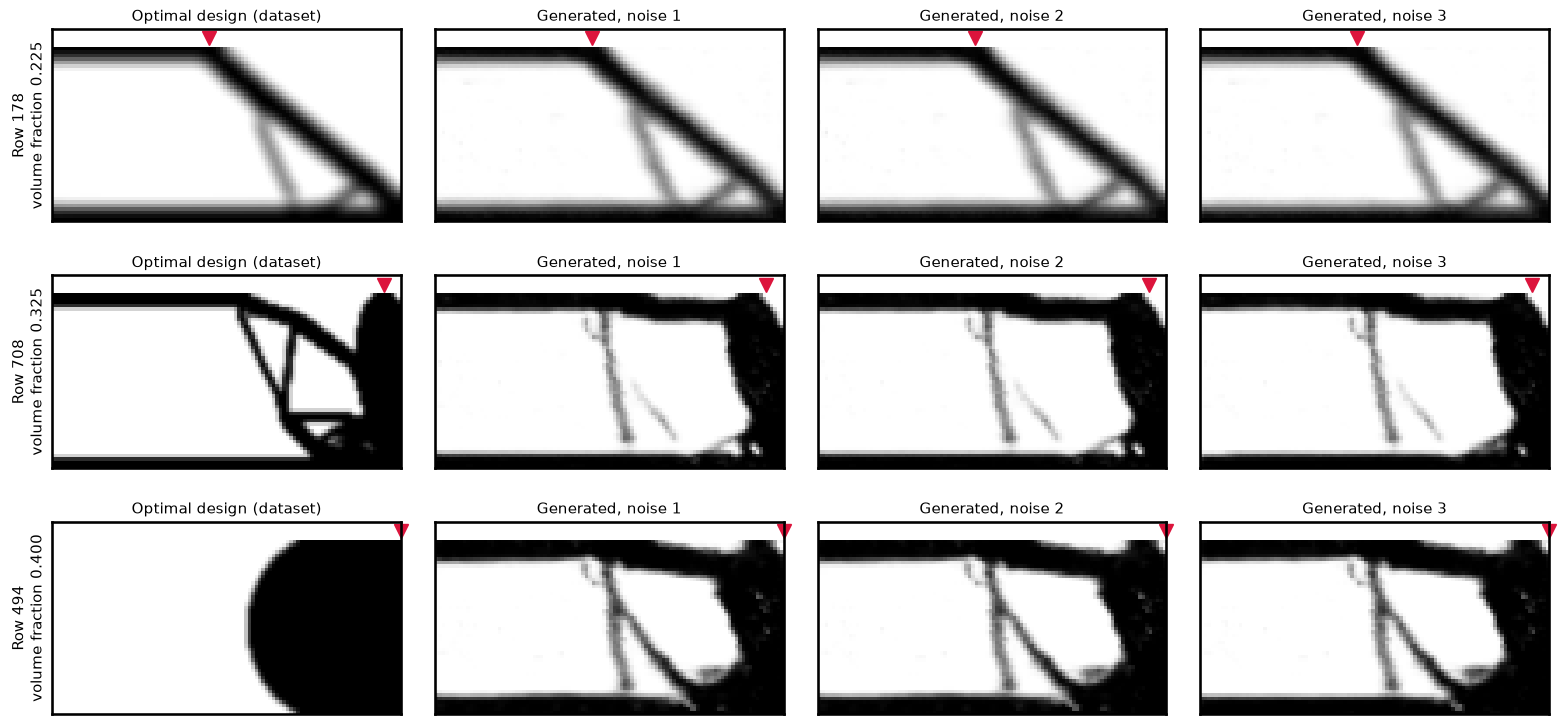

In [24]:
from engibench.problems.beams2d import Beams2D
from engibench_gen_models import CGANGenerator

BEAMS_GENERATOR_PATH = '../../data/beams2d_cgan_generator.pth'
EX3_ROWS = [178, 708, 494]  # rows of the Beams2D validation set used in Exercise 3

beams = Beams2D()
beam_keys = beams.conditions_keys  # volfrac, rmin, forcedist, overhang_constraint
beams_val = beams.dataset['val']

# latent_dim=32 as in the training run that produced the weights (beams2d_cgan_cnn_2d, seed 1)
G_beams = CGANGenerator(latent_dim=32, n_conds=len(beam_keys), design_shape=(50, 100))
G_beams.load_state_dict(torch.load(BEAMS_GENERATOR_PATH, map_location='cpu'))
G_beams.eval()

torch.manual_seed(RNG_SEED)
z_beams = torch.randn(3, 32, 1, 1)  # three noise vectors, used for every row

beam_conditions, beam_optima, beam_designs = [], [], []
for i in EX3_ROWS:
    cond = {k: beams_val[k][i] for k in beam_keys}
    c = torch.tensor([[float(cond[k]) for k in beam_keys]] * 3, dtype=torch.float32).view(3, -1, 1, 1)
    with torch.no_grad():
        # The generator ends in tanh, so map its output from [-1, 1] to densities in [0, 1]
        designs = ((G_beams(z_beams, c) + 1) / 2).numpy().reshape(3, 50, 100)
    beam_conditions.append(cond)
    beam_optima.append(np.array(beams_val['optimal_design'][i]))
    beam_designs.append(designs)

fig, axes = plt.subplots(len(EX3_ROWS), 4, figsize=(16, 2.6 * len(EX3_ROWS)))
for r, (i, cond) in enumerate(zip(EX3_ROWS, beam_conditions)):
    images = [beam_optima[r]] + list(beam_designs[r])
    titles = ['Optimal design (dataset)', 'Generated, noise 1', 'Generated, noise 2', 'Generated, noise 3']
    for ax, im, title in zip(axes[r], images, titles):
        ax.imshow(im, cmap='gray_r', vmin=0, vmax=1, extent=(0, 100, 50, 0))
        ax.plot([100 * cond['forcedist']], [-2.5], marker='v', color='crimson', markersize=10, clip_on=False)  # just above the top edge, so it hides no elements
        ax.set_title(title, fontsize=11)
        ax.set_xticks([])
        ax.set_yticks([])
    axes[r, 0].set_ylabel(f"Row {i}\nvolume fraction {cond['volfrac']:.3f}", fontsize=11)
plt.tight_layout()
plt.show()

::: {.callout-note appearance="simple" icon=false}
### Exercise 3 (~10 min): It looks like a beam
A generated design is only useful if it supports its load as well as the optimal design does.

- (a) From the pictures alone, predict for each row how the compliance of the generated designs compares with the optimal design's: about the same, a few times larger, or far larger. Why?
- (b) Run the cell below. For every design it prints the volume fraction, whether the design passes `beams.check_constraints` (which checks that the volume fraction is within 0.01 of the target), its compliance from `simulate`, and the ratio to the optimal design's compliance. Were your predictions right? Why or why not? Which designs would the constraint check alone have rejected, and why is that check not enough?
- (c) What broke the worst designs? The defect is small, so plot zoomed parts of the generated designs of rows 708 and 494 and of their optima (`beam_designs` and `beam_optima`) in the scratch cell below. Why does a defect of this size change the compliance by a factor of hundreds to thousands?
- (d) The discriminator that trained this generator also saw the four conditions. Why did it not penalize these designs?
- (e) The three designs in each row come from three different noise vectors. Why are they so alike, and what does that mean if you hope to fix a failed design by drawing more samples?
:::

In [25]:
print(f"{'Row':>4} {'design':>10} {'vol. frac.':>10} {'target':>7} {'constraints':>12} {'compliance':>11} {'ratio to optimum':>17}")
for r, (i, cond) in enumerate(zip(EX3_ROWS, beam_conditions)):
    # Beams2D.simulate sets up its load case on the first call and keeps it,
    # so each condition gets a fresh Beams2D object.
    simulator = Beams2D()
    c_opt = float(simulator.simulate(beam_optima[r], config=cond)[0])
    for name, design in [('optimum', beam_optima[r])] + [(f'noise {k + 1}', d) for k, d in enumerate(beam_designs[r])]:
        violations = beams.check_constraints(design, config=cond)
        compliance = float(simulator.simulate(design, config=cond)[0])
        print(f"{i:>4} {name:>10} {design.mean():>10.3f} {cond['volfrac']:>7.3f} "
              f"{'pass' if not violations else 'fail':>12} {compliance:>11.1f} {compliance / c_opt:>17.3g}")

 Row     design vol. frac.  target  constraints  compliance  ratio to optimum
 178    optimum      0.225   0.225         pass       111.0                 1
 178    noise 1      0.227   0.225         pass       115.1              1.04
 178    noise 2      0.227   0.225         pass       115.2              1.04
 178    noise 3      0.221   0.225         pass       118.9              1.07
 708    optimum      0.325   0.325         pass        14.1                 1
 708    noise 1      0.307   0.325         fail     69037.3           4.9e+03
 708    noise 2      0.307   0.325         fail     43874.4          3.11e+03
 708    noise 3      0.305   0.325         fail     35380.3          2.51e+03
 494    optimum      0.400   0.400         pass        18.5                 1
 494    noise 1      0.397   0.400         pass     85550.8          4.62e+03
 494    noise 2      0.398   0.400         pass     15383.5               832
 494    noise 3      0.392   0.400         pass     11177.5     

In [26]:
# You can use this code cell for this exercise, if you like.